In [ ]:
from modules import data_preprocessing as dataPrep
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from termcolor import colored

KITS23_PATH = '/home/marcel/Repos/Data/kits23'
TUMOR_INSTANCE_DATA_PATH = 'data/annotation_empty_75mm.csv'
BBOX_PATH_KT = 'data/data_kt_bbox.csv'
BBOX_PATH_K = 'data/data_k_bbox.csv'

2026-06-21 19:50:49.983687: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
df = dataPrep.extract_tumor_kidney_bounding_boxes(TUMOR_INSTANCE_DATA_PATH, KITS23_PATH)

df.to_csv(BBOX_PATH_KT, index=False)

Calculating bounding boxes:   0%|          | 0/434 [00:00<?, ?it/s]

Calculating bounding boxes: 100%|██████████| 434/434 [20:42<00:00,  2.86s/it]


In [ ]:
df = pd.read_csv(BBOX_PATH_KT)
df

,tumor_id,size_z,size_y,size_x
0,case_00000_t1,215,89,72
1,case_00001_t1,214,117,92
2,case_00001_t2,214,117,92
3,case_00002_t1,112,89,90
4,case_00003_t1,93,101,88
...,...,...,...,...
429,case_00586_t3,37,83,108
430,case_00586_t1,37,79,97
431,case_00586_t2,36,78,97
432,case_00587_t1,23,80,86


In [12]:
df.describe()

,size_z,size_y,size_x
count,434.000000,434.000000,434.000000
mean,59.023041,102.638249,96.735023
std,63.067283,19.526154,18.614388
min,13.000000,57.000000,54.000000
25%,21.000000,89.000000,85.250000
50%,33.000000,102.000000,95.000000
75%,55.500000,114.000000,104.750000
max,291.000000,223.000000,271.000000


<>:62: SyntaxWarning: invalid escape sequence '\m'
<>:62: SyntaxWarning: invalid escape sequence '\s'
<>:62: SyntaxWarning: invalid escape sequence '\m'
<>:62: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_11748/1279660990.py:62: SyntaxWarning: invalid escape sequence '\m'
  ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
/tmp/ipykernel_11748/1279660990.py:62: SyntaxWarning: invalid escape sequence '\s'
  ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')


--- Mean + std ---
limit z = 123
limit y = 123
limit x = 116
--- Mean ---
limit z = 60
limit y = 103
limit x = 97


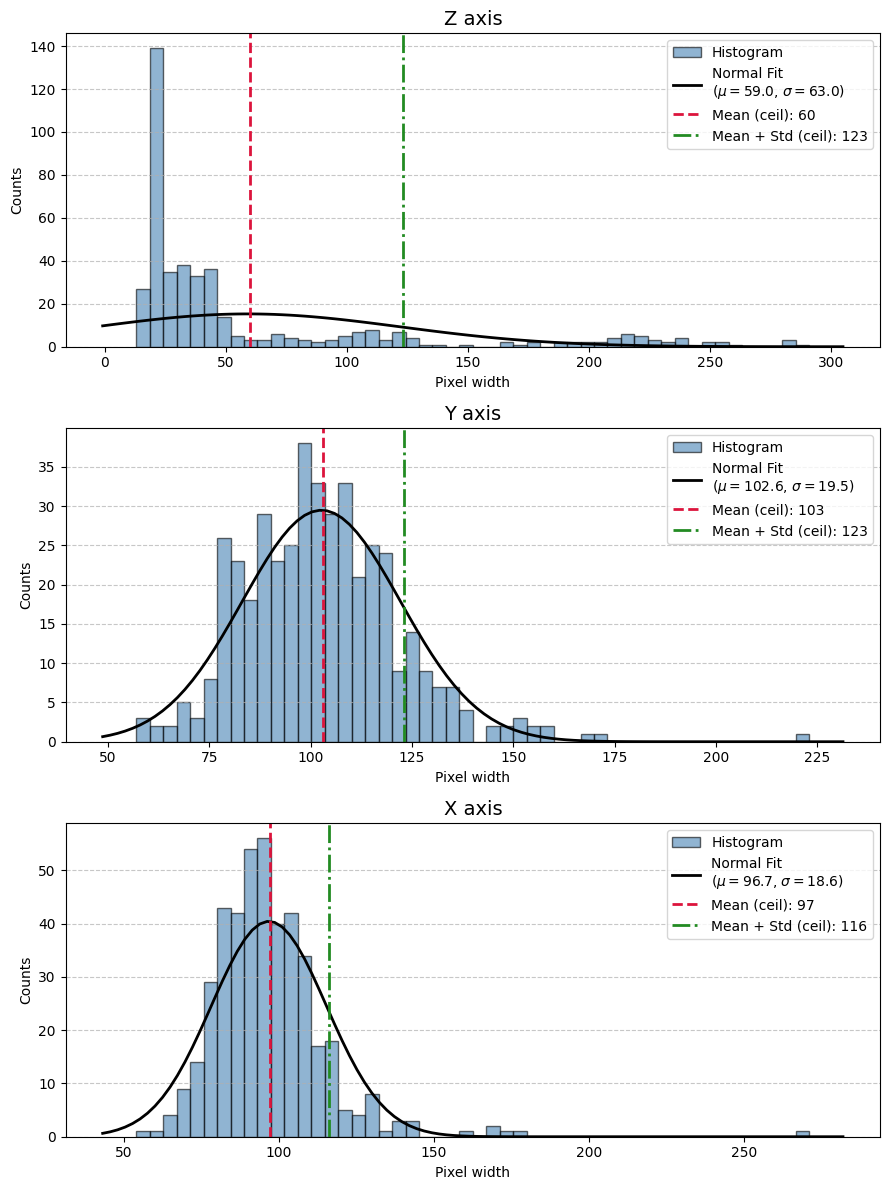

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from termcolor import colored

# Compute the values
# Mean + std limits
limit_z_std = np.ceil(df['size_z'].mean() + df['size_z'].std()).astype('int')
limit_y_std = np.ceil(df['size_y'].mean() + df['size_y'].std()).astype('int')
limit_x_std = np.ceil(df['size_x'].mean() + df['size_x'].std()).astype('int')

print(colored("--- Mean + std ---", "blue"))
print(f"limit z = {limit_z_std}")
print(f"limit y = {limit_y_std}")
print(f"limit x = {limit_x_std}")

# Mean limits
limit_z_mean = np.ceil(df['size_z'].mean()).astype('int')
limit_y_mean = np.ceil(df['size_y'].mean()).astype('int')
limit_x_mean = np.ceil(df['size_x'].mean()).astype('int')

print(colored("--- Mean ---", "blue"))
print(f"limit z = {limit_z_mean}")
print(f"limit y = {limit_y_mean}")
print(f"limit x = {limit_x_mean}")

# --- Plotting ---
# Create a single figure with 3 subplots stacked vertically
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9, 12))

# Group the parameters to iterate cleanly over the axes
variables = [
    ('size_z', 'Z axis', limit_z_mean, limit_z_std),
    ('size_y', 'Y axis', limit_y_mean, limit_y_std),
    ('size_x', 'X axis', limit_x_mean, limit_x_std)
]

for ax, (col, title, mean_val, std_val) in zip(axes, variables):
    # Drop NaNs just in case to avoid issues with norm.fit()
    data = df[col].dropna()
    
    # 1. Plot histogram
    # Remove density=True. Capture the returned bins to calculate bin width.
    counts, bins, patches = ax.hist(data, bins=50, alpha=0.6, color='steelblue', edgecolor='black', label='Histogram')
    
    # Calculate bin width and total number of samples
    bin_width = bins[1] - bins[0]
    n_samples = len(data)
    
    # 2. Fit a normal distribution to the data
    mu, std = norm.fit(data)
    
    # Generate x-values for the fitted distribution curve
    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    
    # Scale the PDF up to match the count scale
    # Formula: PDF * Total Samples * Bin Width
    p = norm.pdf(x, mu, std) * n_samples * bin_width
    
    # Plot the fitted distribution curve
    ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
    
    # 3. Add vertical lines for the computed mean and mean + std values
    ax.axvline(mean_val, color='crimson', linestyle='--', linewidth=2, label=f'Mean (ceil): {mean_val}')
    ax.axvline(std_val, color='forestgreen', linestyle='-.', linewidth=2, label=f'Mean + Std (ceil): {std_val}')
    
    # Formatting
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Counts') # Changed from Density to Count
    ax.set_xlabel('Pixel width')
    ax.legend(loc='upper right')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout so subplots don't overlap
plt.tight_layout()
plt.show()

In [ ]:
df = dataPrep.extract_kidney_bounding_boxes(TUMOR_INSTANCE_DATA_PATH, KITS23_PATH)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from termcolor import colored

# Compute the values
# Mean + std limits
limit_z_std = np.ceil(df['size_z'].mean() + df['size_z'].std()).astype('int')
limit_y_std = np.ceil(df['size_y'].mean() + df['size_y'].std()).astype('int')
limit_x_std = np.ceil(df['size_x'].mean() + df['size_x'].std()).astype('int')

print(colored("--- Mean + std ---", "blue"))
print(f"limit z = {limit_z_std}")
print(f"limit y = {limit_y_std}")
print(f"limit x = {limit_x_std}")

# Mean limits
limit_z_mean = np.ceil(df['size_z'].mean()).astype('int')
limit_y_mean = np.ceil(df['size_y'].mean()).astype('int')
limit_x_mean = np.ceil(df['size_x'].mean()).astype('int')

print(colored("--- Mean ---", "blue"))
print(f"limit z = {limit_z_mean}")
print(f"limit y = {limit_y_mean}")
print(f"limit x = {limit_x_mean}")

# --- Plotting ---
# Create a single figure with 3 subplots stacked vertically
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9, 12))

# Group the parameters to iterate cleanly over the axes
variables = [
    ('size_z', 'Z axis', limit_z_mean, limit_z_std),
    ('size_y', 'Y axis', limit_y_mean, limit_y_std),
    ('size_x', 'X axis', limit_x_mean, limit_x_std)
]

for ax, (col, title, mean_val, std_val) in zip(axes, variables):
    # Drop NaNs just in case to avoid issues with norm.fit()
    data = df[col].dropna()
    
    # 1. Plot histogram
    # Remove density=True. Capture the returned bins to calculate bin width.
    counts, bins, patches = ax.hist(data, bins=50, alpha=0.6, color='steelblue', edgecolor='black', label='Histogram')
    
    # Calculate bin width and total number of samples
    bin_width = bins[1] - bins[0]
    n_samples = len(data)
    
    # 2. Fit a normal distribution to the data
    mu, std = norm.fit(data)
    
    # Generate x-values for the fitted distribution curve
    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    
    # Scale the PDF up to match the count scale
    # Formula: PDF * Total Samples * Bin Width
    p = norm.pdf(x, mu, std) * n_samples * bin_width
    
    # Plot the fitted distribution curve
    ax.plot(x, p, 'k', linewidth=2, label=f'Normal Fit\n($\mu={mu:.1f}$, $\sigma={std:.1f}$)')
    
    # 3. Add vertical lines for the computed mean and mean + std values
    ax.axvline(mean_val, color='crimson', linestyle='--', linewidth=2, label=f'Mean (ceil): {mean_val}')
    ax.axvline(std_val, color='forestgreen', linestyle='-.', linewidth=2, label=f'Mean + Std (ceil): {std_val}')
    
    # Formatting
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Counts') # Changed from Density to Count
    ax.set_xlabel('Pixel width')
    ax.legend(loc='upper right')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout so subplots don't overlap
plt.tight_layout()
plt.show()